# Part E

For each transit-accessibility group, income tercile, and children group, calculate annual parking
expenditure as a share of observed gross income:

(a) averaged over all employees in the group, including non-drivers; and 

(b) averaged over employees who still drive in 2025.

The first quantity describes average exposure across the group; the second describes the
burden among those who actually continue paying. Report the two quantities separately. 

Where
feasible, also show the projected burden under your recommended 2026 tariff, making clear which
behavioural assumptions are used.

## Table

**Required output:** Table E1 with group sample sizes, the two 2025 burden measures, and
the corresponding measure under the recommended tariff if it is projected.

In [73]:
# packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

In [74]:
# Loading data
DAYS_RULE = "cap"
TRANSIT_PATH = "transit_access.csv"
DATA_PATH = "parking_data_clean.csv"
ta = pd.read_csv(TRANSIT_PATH)
raw = pd.read_csv(DATA_PATH)

In [75]:
def prepare(raw, rule):
    """Same merge as Part B, plus the days rule and a car-user flag."""
    x = (raw.drop(columns=["transit_group", "transit_score"], errors="ignore")
            .merge(ta[["home_commune", "site", "transit_score", "transit_group"]],
                   on=["home_commune", "site"], how="left", validate="m:1"))
    bad = x["car_days_per_week"] > 5
    if rule == "cap":
        x.loc[bad, "car_days_per_week"] = 5.0
    elif rule == "drop":
        x = x[~bad]
    x = x.sort_values(["employee_id", "year"]).reset_index(drop=True)
    x["car_user"] = x["car_days_per_week"] > 0
    x["male"] = (x["gender"] == "M").astype(float)
    return x

df = prepare(raw, DAYS_RULE)

In [76]:
df.head()

,employee_id,site,year,parking_fee_chf,main_mode,uses_car,car_days_per_week,home_commune,home_postcode,distance_km,age,gender,n_children,fte,gross_income_chf,income_imputed,transit_score,transit_group,car_user,male
0,E1000,Lausanne,2024,2.0,car,1,2.2,Lausanne,1004,2.9,23,M,0,0.8,59300.0,False,0.813659,High,True,1.0
1,E1000,Lausanne,2025,4.0,car,1,2.0,Lausanne,1004,2.9,23,M,0,0.8,59300.0,False,0.813659,High,True,1.0
2,E1001,Lausanne,2024,2.0,car,1,3.5,Le Mont-Sur-Lausanne,1052,5.6,51,F,1,1.0,124300.0,False,0.196175,Medium,True,0.0
3,E1001,Lausanne,2025,4.0,car,1,5.0,Le Mont-Sur-Lausanne,1052,5.6,51,F,1,1.0,124300.0,False,0.196175,Medium,True,0.0
4,E1002,Lausanne,2024,2.0,car,1,2.6,Chavannes-Près-Renens,1022,7.7,39,M,0,1.0,72800.0,False,0.390677,High,True,1.0


In [77]:
d25 = df[df["year"] == 2025].set_index("employee_id")

emp = pd.DataFrame({
    "site": d25["site"],
    "car25": d25["uses_car"],
    "days25": d25["car_days_per_week"],
    "income25": d25["gross_income_chf"],
    "n_children": d25["n_children"],
    "transit_group": d25["transit_group"],
    "transit_score": d25["transit_score"],
    "distance25": d25["distance_km"], "age25": d25["age"], "fte25": d25["fte"],
    "male25": d25["male"],
    "parking_fee_chf": d25["parking_fee_chf"]
})

emp["transit_group"] = pd.Categorical(emp["transit_group"], categories=["Low", "Medium", "High"], ordered=True)
emp["income_tercile"] = pd.qcut(emp["income25"], 3, labels=["Low", "Middle", "High"])
emp["children_grp"] = emp["n_children"].map({0: "0", 1: "1", 2: "2+"})
emp["All"] = "All car users"

print(emp["income25"].quantile([1/3, 2/3]))             # must match Part B: 77,500 and 103,200

0.333333     77500.0
0.666667    103200.0
Name: income25, dtype: float64


In [78]:
# ------------------------------------------------------------
# Table E1 – share of **annual** gross income used for parking
# ------------------------------------------------------------
#  • 46 working weeks are assumed per year.
#  • Three site‑scenarios: Lausanne only, Sion only, Both sites.
#  • Four groupings: All, transit_group, income_tercile, children_grp.
#  • Columns:
#        * Sample size (all employees in the subgroup)
#        * Share of annual gross income spent on parking for
#          – all employees
#          – drivers only (car25 == 1)
# ------------------------------------------------------------

# ------------------------------------------------------------------
# Helper: compute the three statistics for a single dataframe slice
# ------------------------------------------------------------------
def _stats_one_slice(df_slice: pd.DataFrame) -> dict:
    """
    Returns a dict with:
    * Sample size (all employees)
    * Share of *annual* gross income used for parking
      – for all employees
      – for drivers only
    """
    # ----- counts ---------------------------------------------------
    n_all = len(df_slice)
    # drivers only
    drivers = df_slice[df_slice["car25"] == 1]
    n_drv = len(drivers)
    # ----- weekly burden (parking_fee × days per week) -------------
    weekly_burden_all = (df_slice["parking_fee_chf"] *
                         df_slice["days25"]).mean()
    weekly_burden_drv = (drivers["parking_fee_chf"] *
                         drivers["days25"]).mean()
    # ----- convert to **annual** burden (46 working weeks) ---------
    annual_burden_all = weekly_burden_all * 46
    annual_burden_drv = weekly_burden_drv * 46
    # ----- total gross income for the relevant population ---------
    income_all = df_slice["income25"].sum()
    income_drv = drivers["income25"].sum()
    # ----- share of annual gross income -----------------------------
    # for a given population (e.g., all Lausanne workers), what fraction of the total 
    # income is consumed by parking. This is the unbiased measure of overall fiscal burden.
    share_all = (annual_burden_all * n_all) / income_all \
                if income_all != 0 else np.nan
    share_drv = (annual_burden_drv * n_drv) / income_drv \
                if income_drv != 0 else np.nan
    return {
        "Sample size": n_all,
        "Share all":     share_all,
        "Share drivers": share_drv,
    }
# ------------------------------------------------------------------
# Base data – 2025 rows for both sites (already in `emp`)
# ------------------------------------------------------------------
base = emp[emp["site"].isin(["Lausanne", "Sion"])]
# ------------------------------------------------------------------
# Site scenarios
# ------------------------------------------------------------------
site_cases = {
    "Lausanne": base[base["site"] == "Lausanne"],
    "Sion":     base[base["site"] == "Sion"],
    "Both":     base,                     # combined Lausanne + Sion
}
# ------------------------------------------------------------------
# Groupings we need
# ------------------------------------------------------------------
groupings = {
    "Overall":          None,                # whole set as one group
    "Transit access":   "transit_group",
    "Income tercile":   "income_tercile",
    "Number of children": "children_grp",
}
rows = []          # rows that will become the final DataFrame
idx  = []          # MultiIndex tuples (site, grouping, subgroup)
for site_name, df_site in site_cases.items():
    for grp_label, grp_col in groupings.items():
        # ------------------------------------------------------------
        # Build the groups for this site‑scenario
        # ------------------------------------------------------------
        if grp_col is None:          # “Overall” – treat whole df as one group
            groups = [(grp_label, df_site)]
        else:
            groups = df_site.groupby(grp_col, observed=True)
        for g_val, sub in groups:
            stats = _stats_one_slice(sub)
            # `g_val` is the subgroup label (e.g. “High”, “Low”, …)
            subgroup_label = g_val if grp_col is not None else grp_label
            rows.append({
                "Site":          site_name,
                "Grouping":      grp_label,
                "Subgroup":      subgroup_label,
                **stats,
            })
            idx.append((site_name, grp_label, subgroup_label))
# ------------------------------------------------------------------
# Assemble the final table (3‑level index)
# ------------------------------------------------------------------
E1 = pd.DataFrame(rows)
E1.set_index(["Site", "Grouping", "Subgroup"], inplace=True)
# Optional: round the share columns for nicer printing
E1 = E1.round(4)
# ------------------------------------------------------------
# Display the result
# ------------------------------------------------------------
print(E1)

                                      Sample size  Share all  Share drivers
Site     Grouping           Subgroup                                       
Lausanne Overall            Overall           800     0.0029         0.0062
         Transit access     Low                68     0.0064         0.0077
                            Medium            207     0.0038         0.0066
                            High              525     0.0021         0.0056
         Income tercile     Low               253     0.0035         0.0094
                            Middle            261     0.0031         0.0071
                            High              282     0.0026         0.0048
         Number of children 0                 421     0.0019         0.0051
                            1                 155     0.0034         0.0065
                            2+                224     0.0047         0.0074
Sion     Overall            Overall           200     0.0024         0.0038
         Tra

/var/folders/9d/khh6c2zs2m544t16sgvptfbr0000gn/T/ipykernel_29830/400226341.py:100: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  E1.set_index(["Site", "Grouping", "Subgroup"], inplace=True)


## Create image

In [79]:
# ---- table helpers (same look as Tables B1-B3) ----------------------------------
plt.rcParams.update({"font.family": "serif", "font.serif": ["STIXGeneral", "DejaVu Serif"]})

def make_fmt(spec):
    """spec: column name -> format string; default 2 decimals."""
    def f(v, col):
        if pd.isna(v):
            return "–"
        if col == "p-value" and v < 0.001:
            return "<0.001"
        s = spec.get(col, "{:.2f}").format(v)
        if float(s) == 0:                      # avoid "-0.00"
            s = s.lstrip("-")
        return s.replace("-", "−")
    return f

def booktabs_panels(B, headers, title, note, fname, fmt, label_w=2.4, col_w=1.5, row_h=0.36):
    cols = list(B.columns)
    rows = []
    for p in dict.fromkeys(B.index.get_level_values(0)):
        if p != "Overall":
            rows.append(("panel", p, None))
        for g, r in B.loc[p].iterrows():
            rows.append(("overall" if p == "Overall" else "row", g, [fmt(r[c], c) for c in cols]))
    n_hdr = 2 * row_h
    width = label_w + col_w * len(cols)
    height = n_hdr + row_h * len(rows) + 1.4
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width); ax.set_ylim(0, height); ax.axis("off")
    top = height - 0.7
    xc = lambda j: label_w + col_w * (j + 0.5)
    ax.text(width / 2, height - 0.25, title, ha="center", va="center", fontsize=12, weight="bold")
    for j, h in enumerate(headers):
        ax.text(xc(j), top - n_hdr / 2, h, ha="center", va="center", weight="bold", fontsize=10)
    ax.hlines(top, 0, width, color="black", lw=1.6)
    ax.hlines(top - n_hdr, 0, width, color="black", lw=0.7)
    y = top - n_hdr
    for k, (kind, label, vals) in enumerate(rows):
        yc = y - row_h / 2
        if kind == "panel":
            if k > 0:
                ax.hlines(y, 0, width, color="black", lw=0.4)
            ax.text(0.05, yc, label, ha="left", va="center", fontsize=10, style="italic", weight="bold")
        else:
            ax.text(0.05 if kind == "overall" else 0.3, yc, label, ha="left", va="center", fontsize=10)
            for j, v in enumerate(vals):
                ax.text(xc(j), yc, v, ha="center", va="center", fontsize=10)
        y -= row_h
    ax.hlines(y, 0, width, color="black", lw=1.6)
    ax.text(0, y - 0.3, note, ha="left", va="top", fontsize=8.5)
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

def booktabs(t, title, fname, col_w=1.9, label_w=3.2, row_h=0.38, header_h=None,
             header_fs=10, body_fs=11, rule_after=()):
    """t = DataFrame of strings (same function as Table B1)."""
    n_rows, n_cols = t.shape
    widths = [col_w] * n_cols if np.isscalar(col_w) else list(col_w)
    xs = label_w + np.concatenate([[0], np.cumsum(widths)])
    width = xs[-1]
    header_h = header_h or row_h
    height = header_h + row_h * n_rows + 0.9
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width); ax.set_ylim(0, height); ax.axis("off")
    top = height - 0.6
    body_top = top - header_h
    bottom = body_top - row_h * n_rows
    for j, c in enumerate(t.columns):
        ax.text((xs[j] + xs[j + 1]) / 2, top - header_h / 2, c, ha="center", va="center",
                weight="bold", fontsize=header_fs, linespacing=1.1)
    for i, (lab, row) in enumerate(t.iterrows()):
        y = body_top - row_h * (i + 0.5)
        ax.text(0.1, y, lab, ha="left", va="center", fontsize=body_fs)
        for j, v in enumerate(row):
            ax.text((xs[j] + xs[j + 1]) / 2, y, str(v), ha="center", va="center", fontsize=body_fs)
    ax.hlines(top, 0, width, color="black", lw=1.6)
    ax.hlines(body_top, 0, width, color="black", lw=0.7)
    ax.hlines(bottom, 0, width, color="black", lw=1.6)
    for k in rule_after:
        ax.hlines(body_top - row_h * k, 0, width, color="black", lw=0.4)
    ax.text(0, bottom - 0.3, "", fontsize=8)
    ax.text(width / 2, height - 0.2, title, ha="center", va="center", fontsize=12, weight="bold")
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

In [80]:
# ------------------------------------------------------------
# 0️⃣  Remove stray built‑in shadows that might exist right now
# ------------------------------------------------------------
for name in ["dict", "list", "str", "int", "float"]:
    if name in globals() and not isinstance(globals()[name], type):
        del globals()[name]          # delete the accidental variable

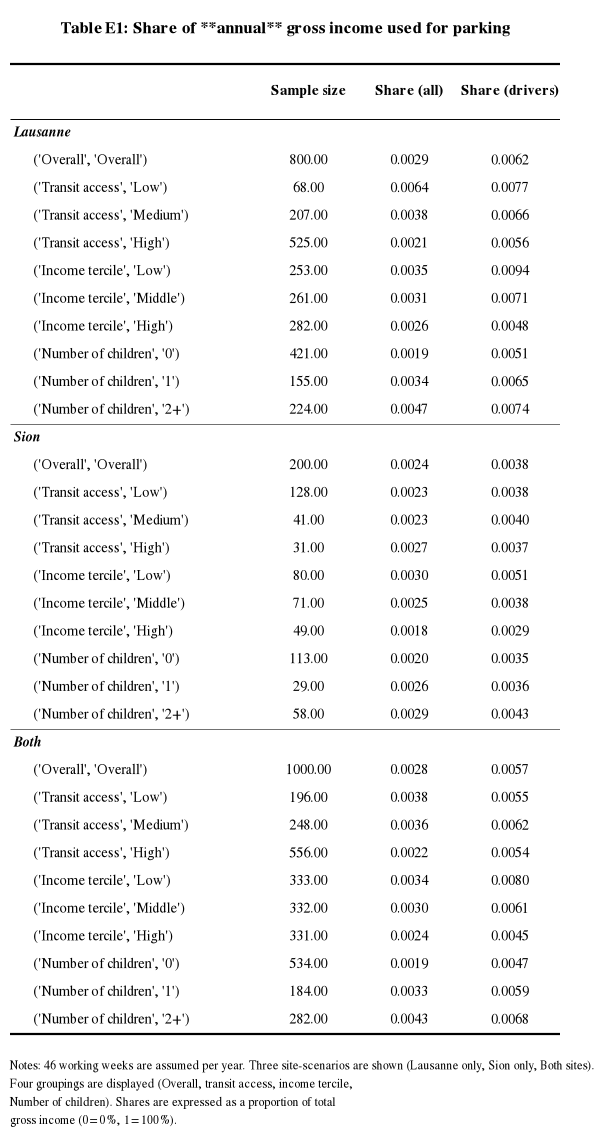


✅  Table saved – open `table_E1.png` to confirm the content.


In [81]:
col_order = ["Sample size", "Share all", "Share drivers"]
col_names = ["Sample size", "Share (all)", "Share (drivers)"]
caption = "Table E1: Share of **annual** gross income used for parking"
note = (
    "Notes: 46 working weeks are assumed per year. "
    "Three site‑scenarios are shown (Lausanne only, Sion only, Both sites). \n"
    "Four groupings are displayed (Overall, transit access, income tercile, \n"
    "Number of children). Shares are expressed as a proportion of total \n"
    "gross income (0 = 0 %, 1 = 100 %)."
)
booktabs_panels(
    E1[col_order],               # numeric columns only
    col_names,                   # header labels
    caption,                     # caption under the table
    note,                        # footnote
    "table_E1.png",              # a **new** file name – nothing is overwritten
    fmt=make_fmt({               # format function from the original helper
        "Share all":   "{:.4f}",
        "Share drivers": "{:.4f}",
    }),
    label_w=3.2,
    col_w=1.3
)

print("\n✅  Table saved – open `table_E1.png` to confirm the content.")

Some insights from the above table: 
- The share is always bigger for drivers only which is obvious
- The share is highest for: medium transit access, low income tercile,and 2+ children. It is lowest for: low transit access, high income tercile and no children. This remains true in both working sites. 

Table B2 provides the elasticity for the different groups in Lausanne. Its magnitude is highest for low transit access, low income tercile and absence of children. Its magnitude is lowest for medium transit access, high income tercile and 2+ children. 

## Interpretation

In [82]:
# ------------------------------------------------------------------
# 6️⃣  Summarise results in the format requested in the assignment
# ------------------------------------------------------------------
# ----  Share (same pattern for both sites) ----
share_summary = pd.DataFrame({
    "Dimension": ["Transit access", "Income tercile", "Children"],
    "Highest share": [
        "Low",   # transit
        "Low",      # income
        "2+ children"
    ],
    "Lowest share": [
        "High",      # transit
        "High",     # income
        "No children"
    ]
})
# ---- Elasticity (Lausanne only) ----
elasticity_summary = pd.DataFrame({
    "Dimension": ["Transit access", "Income tercile", "Children"],
    "Largest magnitude": [
        "High",          # transit
        "Low",          # income
        "No children"
    ],
    "Smallest magnitude": [
        "Low",       # transit
        "High",         # income
        "2+ children"
    ]
})
# ------------------------------------------------------------------
# 7️⃣  Display the two tables
# ------------------------------------------------------------------
print("\n=== Share of annual gross income (burden, Table E1) ===")
print(share_summary.to_string(index=False))
print("\n=== Elasticity (responsiveness) – Lausanne (Table B2) ===")
print(elasticity_summary.to_string(index=False))


=== Share of annual gross income (burden, Table E1) ===
     Dimension Highest share Lowest share
Transit access           Low         High
Income tercile           Low         High
      Children   2+ children  No children

=== Elasticity (responsiveness) – Lausanne (Table B2) ===
     Dimension Largest magnitude Smallest magnitude
Transit access              High                Low
Income tercile               Low               High
      Children       No children        2+ children


Interpret the results using both responsiveness and burden. Address the following questions:

1) Does a weak response indicate low burden, or could it indicate a lack of alternatives?

Only the high income tercile has the weak response and a low burden simultenously. As money is not an issue, there is no incentive to change habits. 

The low transit access group has a weak response but has the highest burden. This can be an indicator that transport alternatives are lacking for this group. 

Furthermore, the 2+ children group has a weak response but the highest burden. A hypothesis could be that with small children, it is a lot easier to bring them to school or other by car than with other means of transport. This easiness factor has priority over the financial burden. Transport alternatives are also lacking for this group

2) Which groups obtain the largest behavioural benefit, and which groups contribute to the most revenue?

Groups with largest elasticity: high transit access, low income tercile, no children.
Groups whose share of income for the parking is highest: low transit access, low income tercile and 2+ children.

3) Are there groups for whom a uniform tariff creates a foreseeable equity or feasibility problem?

Using the same price for everyone creates an equity problem as some groups (like the low transit access and the 2+ children groups) do not benefit from behavioural change and have the highest financial burden at the same time. 


Do not infer welfare, savings, or public-transport costs that are not observed in the data.